In [44]:
import pandas as pd

In [45]:
df=pd.read_csv("d:\\project\\8. Logistic Regression\\8. Logistic Regression\\diabetes.csv")

In [46]:
df.head()



,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [47]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [48]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [49]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [50]:
df.dtypes

Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

In [51]:
df.duplicated().sum()

np.int64(0)

In [52]:
for col in df.columns:
    print(col, ":", df[col].unique())

Pregnancies : [ 6  1  8  0  5  3 10  2  4  7  9 11 13 15 17 12 14]
Glucose : [148  85 183  89 137 116  78 115 197 125 110 168 139 189 166 100 118 107
 103 126  99 196 119 143 147  97 145 117 109 158  88  92 122 138 102  90
 111 180 133 106 171 159 146  71 105 101 176 150  73 187  84  44 141 114
  95 129  79   0  62 131 112 113  74  83 136  80 123  81 134 142 144  93
 163 151  96 155  76 160 124 162 132 120 173 170 128 108 154  57 156 153
 188 152 104  87  75 179 130 194 181 135 184 140 177 164  91 165  86 193
 191 161 167  77 182 157 178  61  98 127  82  72 172  94 175 195  68 186
 198 121  67 174 199  56 169 149  65 190]
BloodPressure : [ 72  66  64  40  74  50   0  70  96  92  80  60  84  30  88  90  94  76
  82  75  58  78  68 110  56  62  85  86  48  44  65 108  55 122  54  52
  98 104  95  46 102 100  61  24  38 106 114]
SkinThickness : [35 29  0 23 32 45 19 47 38 30 41 33 26 15 36 11 31 37 42 25 18 24 39 27
 21 34 10 60 13 20 22 28 54 40 51 56 14 17 50 44 12 46 16  7 52 43 48  8


In [53]:
df['Outcome'].value_counts()

Outcome
0    500
1    268
Name: count, dtype: int64

<function matplotlib.pyplot.show(close=None, block=None)>

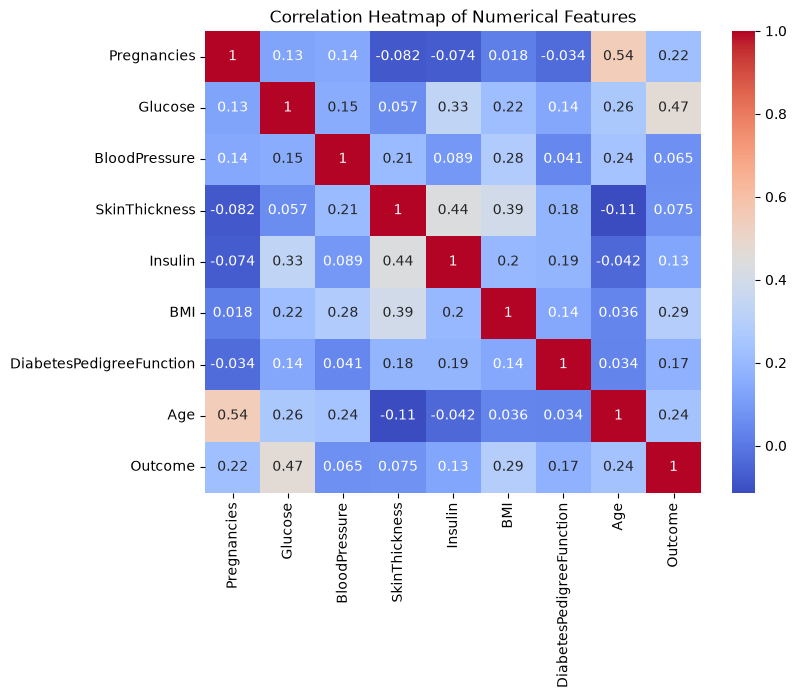

In [54]:
import matplotlib.pyplot as plt
import seaborn as sns

#correlation heatmap of numerical features
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(numeric_only=True), annot= True, cmap='coolwarm')
plt.title('Correlation Heatmap of Numerical Features')
plt.show

Glucose has the strongest correlation with the pregnancies, glucose maybe an important feature for predicting diabetes.
BMI has a weak positive correlation with pregnancies, but have association with diabetes
Age and Pregnancies have weak positive correlations.
Age and the number of pregnancies have some relationship with the diabetes outcome


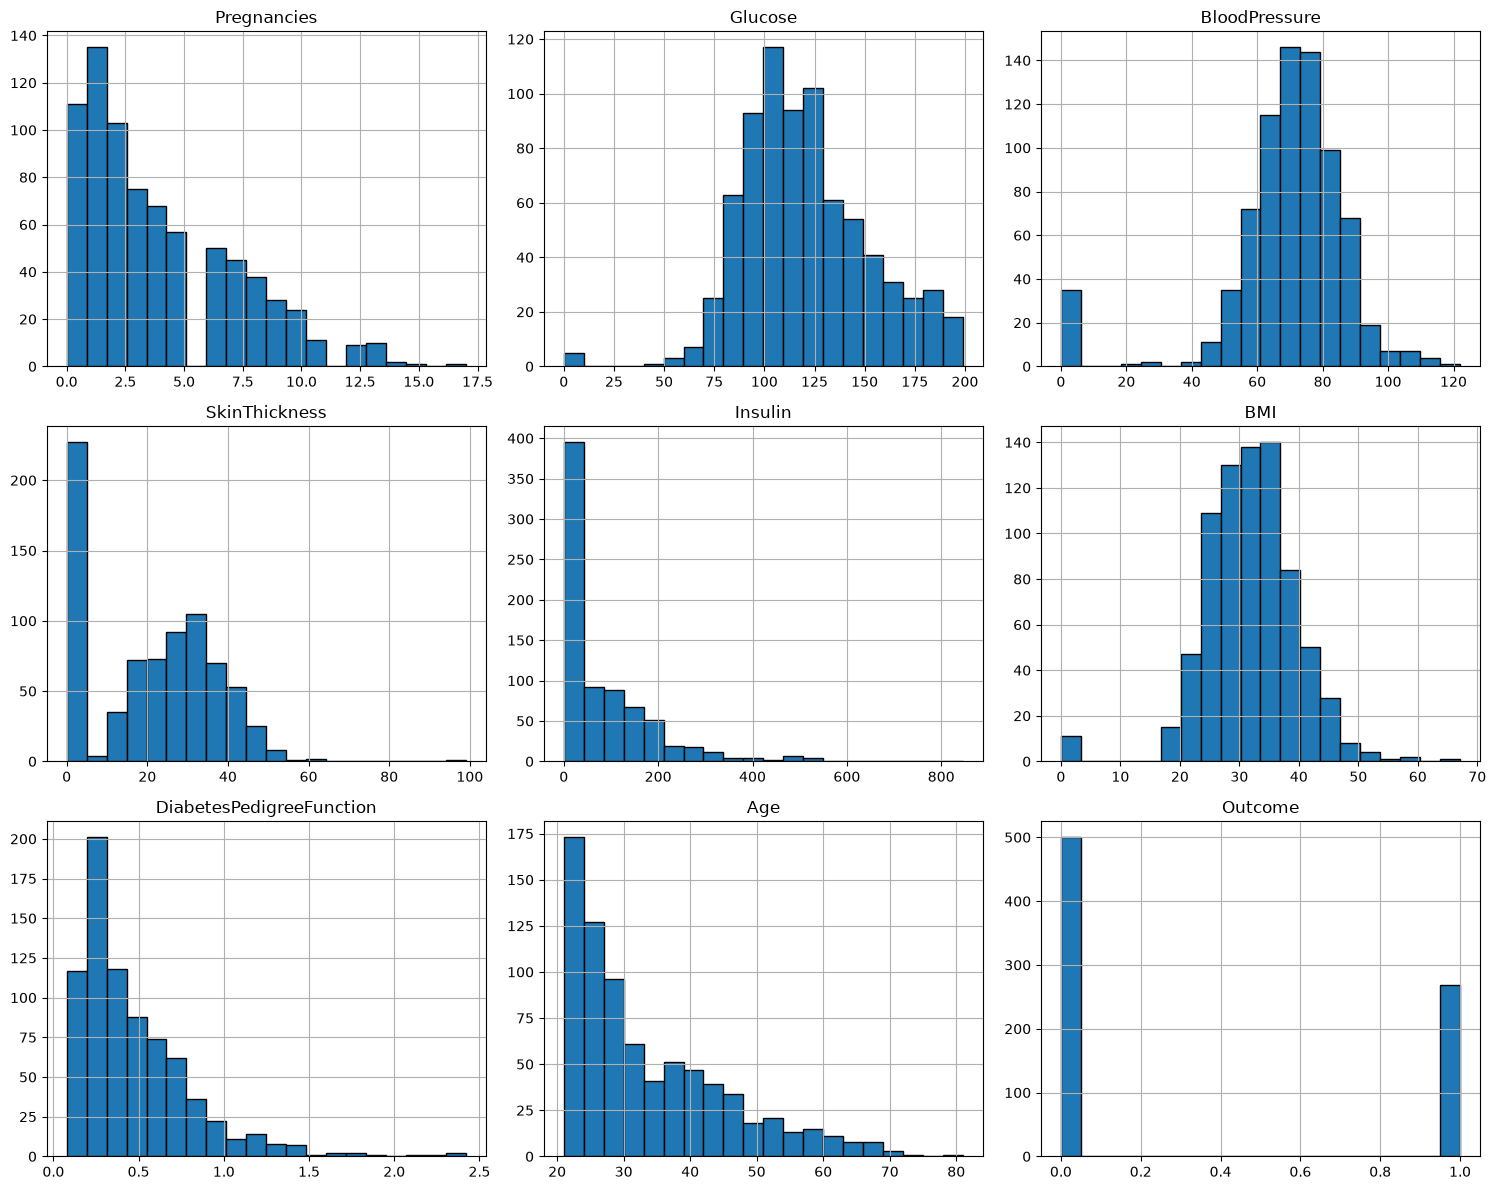

In [55]:
df.hist(figsize=(15, 12), bins=20, edgecolor='black')
plt.tight_layout()
plt.show()

Pregnancies-
The distribution is right skewed, the frequencies decreases as the number of pregnancies increases.


Glucose-
The distribution is approximately bell-shaped but slighlty right skewed.


Blood Pressure- 
The distribution is normal, several observation have a value of zero, which is unusaul and may represent missing data.


Skin Thickness-
The distribution is positively skewed. large number of observation have a value of zero


Insulin-
The distribution is highly positivley skewed, a few observation have very high insulin, indicating potential outliers.


BMI-
The distribution is approximately bell shaped, a few observation have a zero  BMI, which is not a relaistic measurement


Diabetes- The distribution is positively skewed.


Age- The distribuution is positively skewed, frequency decreases as age increases, a few older individual are present.


Outcome- 0 represent individual without diabetes, 1 represent individual with diabetes, there are more records with outcome 0 than outcome 1.

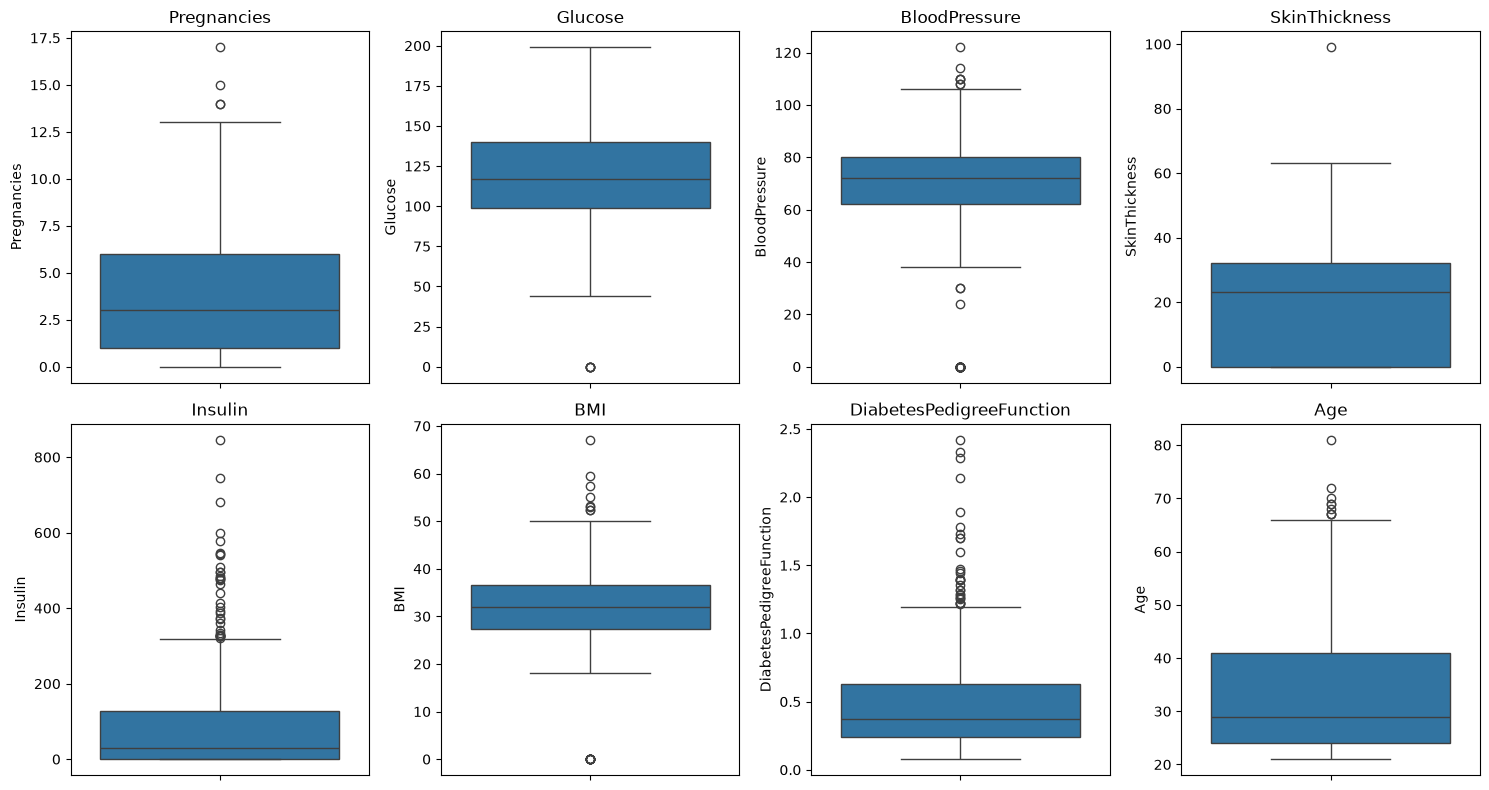

In [56]:
plt.figure(figsize=(15, 8))

for i, col in enumerate(df.columns.drop('Outcome'), 1):
    plt.subplot(2, 4, i)
    sns.boxplot(y=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

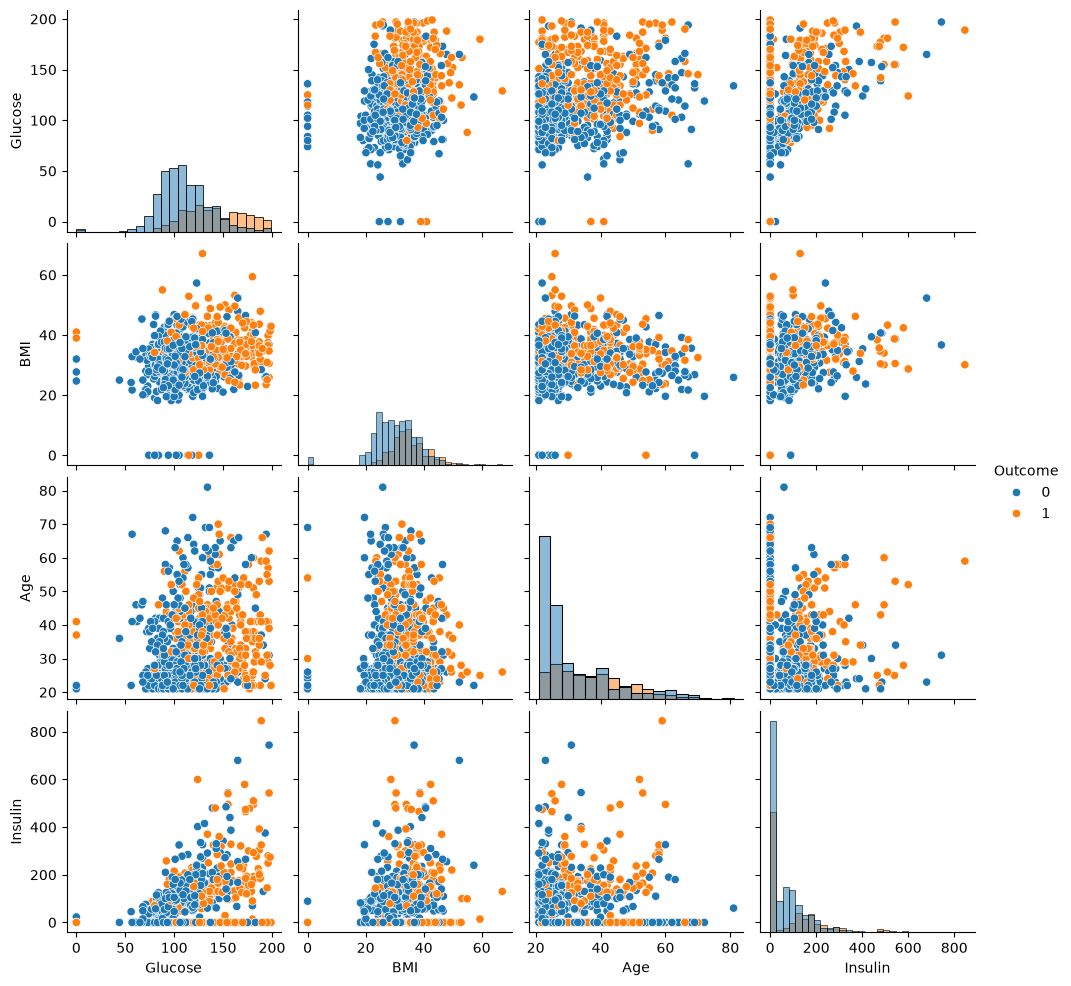

In [57]:
selected_cols = [
    'Glucose',
    'BMI',
    'Age',
    'Insulin',
    'Outcome'
]

sns.pairplot(
    df[selected_cols],
    hue='Outcome',
    diag_kind='hist'
)

plt.show()

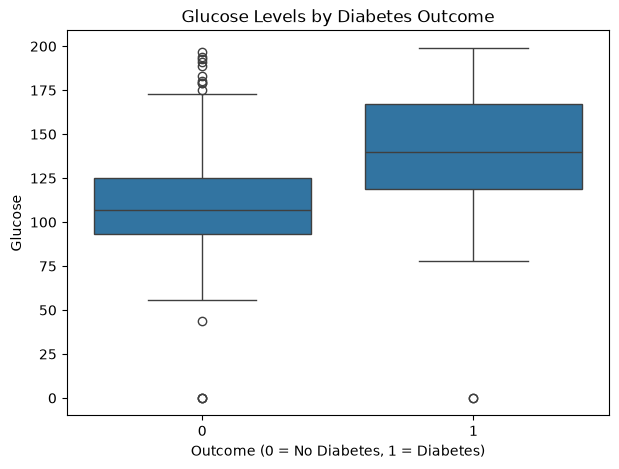

In [58]:
plt.figure(figsize=(7, 5))

sns.boxplot(data=df, x='Outcome', y='Glucose')

plt.title('Glucose Levels by Diabetes Outcome')
plt.xlabel('Outcome (0 = No Diabetes, 1 = Diabetes)')
plt.ylabel('Glucose')
plt.show()

Building a regression model to predict diabetes outcome based on the features in the dataset. We will use logistic regression for this classification task.

In [76]:
#check and treat invalid zeros
import numpy as np

invalid_columns = [
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI'
]

# Check zero counts
print((df[invalid_columns] == 0).sum())

Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64


In [77]:
from sklearn.model_selection import train_test_split

X = df.drop('Outcome', axis=1)
y = df['Outcome']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(614, 8)
(154, 8)


In [78]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('logistic', LogisticRegression(max_iter=1000))
])

# Train the model
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

# Prediction probabilities
y_prob = model.predict_proba(X_test)[:, 1]

In [79]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("ROC AUC:", roc_auc_score(y_test, y_prob))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.7077922077922078
Precision: 0.6
Recall: 0.5
F1 Score: 0.5454545454545454
ROC AUC: 0.812962962962963

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.82      0.78       100
           1       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154


Confusion Matrix:
[[82 18]
 [27 27]]


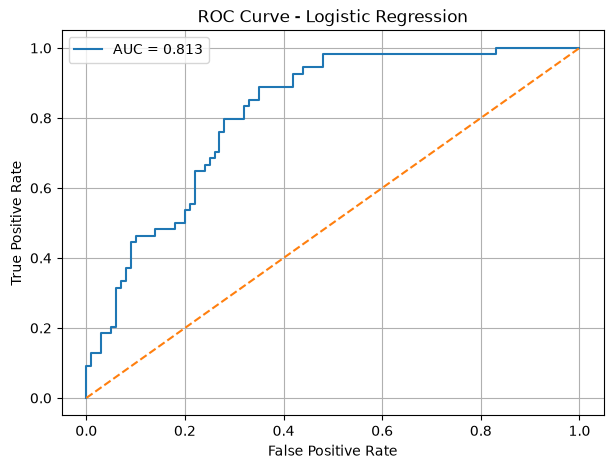

In [80]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

auc_score = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(7, 5))

plt.plot(fpr, tpr, label=f'AUC = {auc_score:.3f}')

plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.title('ROC Curve - Logistic Regression')

plt.legend()
plt.grid()
plt.show()

Diabetes Prediction Model using Logistic Regression

In [81]:
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

In [82]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (614, 8)
Testing data: (154, 8)


In [83]:
model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(max_iter=1000))
])

In [84]:
model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [85]:
# Predict diabetes outcomes
y_pred = model.predict(X_test)

print("Predicted values:")
print(y_pred)

print("\nActual values:")
print(y_test.values)

Predicted values:
[1 0 0 0 0 0 0 1 0 1 0 0 0 0 0 0 1 0 1 0 0 1 0 1 1 0 1 0 0 0 0 0 0 1 1 0 0
 0 1 1 0 0 0 0 0 0 0 0 1 0 1 1 0 0 1 0 1 0 1 0 1 0 0 1 0 0 1 0 0 1 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 1 1 0 1 1 0 0 0 0 0 1 0 1 0 1 0 1
 1 0 0 0 0 0 0 1 0 1 0 0 1 0 1 1 1 0 0 0 1 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 1
 0 0 0 0 1 0]

Actual values:
[0 0 0 1 0 0 1 1 0 0 0 1 0 0 1 1 0 0 0 0 0 1 1 1 0 0 1 0 1 0 0 0 0 0 0 1 0
 0 1 0 0 0 0 1 0 1 1 0 1 1 0 1 0 0 0 0 1 0 1 0 1 0 0 1 0 0 1 0 0 1 1 0 0 1
 0 1 0 1 0 0 0 0 0 0 0 0 1 1 0 0 1 1 0 1 1 1 0 0 1 0 0 0 0 0 1 0 1 0 0 0 0
 1 1 1 1 0 0 0 1 0 0 1 0 0 1 1 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 1 1 1
 0 0 0 0 1 0]


In [86]:
y_prob = model.predict_proba(X_test)

print(y_prob[:10])

[[0.39028927 0.60971073]
 [0.88164424 0.11835576]
 [0.70653687 0.29346313]
 [0.7491633  0.2508367 ]
 [0.96679333 0.03320667]
 [0.83147615 0.16852385]
 [0.5118357  0.4881643 ]
 [0.07632489 0.92367511]
 [0.91856595 0.08143405]
 [0.1614104  0.8385896 ]]


In [87]:
diabetes_probability = model.predict_proba(X_test)[:, 1]

print(diabetes_probability[:10])

[0.60971073 0.11835576 0.29346313 0.2508367  0.03320667 0.16852385
 0.4881643  0.92367511 0.08143405 0.8385896 ]


In [88]:
results = pd.DataFrame({
    'Actual Outcome': y_test.values,
    'Predicted Outcome': y_pred,
    'Diabetes Probability': diabetes_probability
})

print(results.head(10))

   Actual Outcome  Predicted Outcome  Diabetes Probability
0               0                  1              0.609711
1               0                  0              0.118356
2               0                  0              0.293463
3               1                  0              0.250837
4               0                  0              0.033207
5               0                  0              0.168524
6               1                  0              0.488164
7               1                  1              0.923675
8               0                  0              0.081434
9               0                  1              0.838590


In [91]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

In [92]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100)

precision = precision_score(y_test, y_pred)

print("Precision:", precision)


recall = recall_score(y_test, y_pred)

print("Recall:", recall)


f1 = f1_score(y_test, y_pred)

print("F1 Score:", f1)

auc = roc_auc_score(y_test, diabetes_probability)

print("ROC-AUC Score:", auc)

Accuracy: 0.7077922077922078
Accuracy Percentage: 70.77922077922078
Precision: 0.6
Recall: 0.5
F1 Score: 0.5454545454545454
ROC-AUC Score: 0.812962962962963


[[82 18]
 [27 27]]


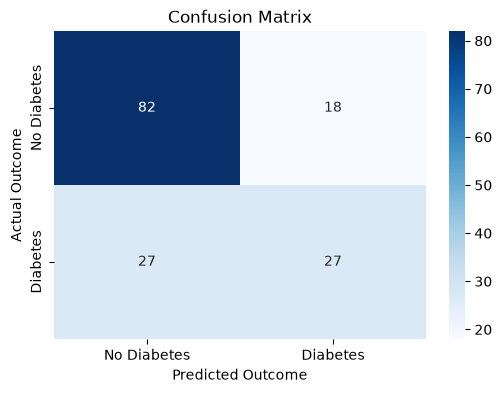

In [93]:
cm = confusion_matrix(y_test, y_pred)

print(cm)
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Diabetes', 'Diabetes'],
    yticklabels=['No Diabetes', 'Diabetes']
)

plt.xlabel("Predicted Outcome")
plt.ylabel("Actual Outcome")
plt.title("Confusion Matrix")

plt.show()

In [94]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.75      0.82      0.78       100
           1       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154



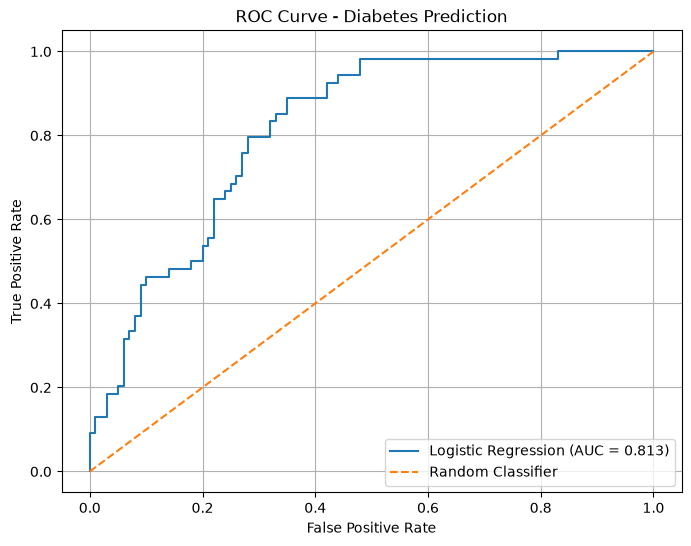

In [95]:
from sklearn.metrics import roc_curve, roc_auc_score

# Calculate FPR and TPR
fpr, tpr, thresholds = roc_curve(
    y_test,
    diabetes_probability
)

# Calculate AUC
auc = roc_auc_score(y_test, diabetes_probability)

# Plot ROC curve
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f'Logistic Regression (AUC = {auc:.3f})'
)

# Random classifier reference line
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Diabetes Prediction')

plt.legend()
plt.grid()
plt.show()

In [96]:
evaluation = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Precision',
        'Recall',
        'F1 Score',
        'ROC-AUC'
    ],
    'Score': [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred),
        roc_auc_score(y_test, diabetes_probability)
    ]
})

print(evaluation)

      Metric     Score
0   Accuracy  0.707792
1  Precision  0.600000
2     Recall  0.500000
3   F1 Score  0.545455
4    ROC-AUC  0.812963


The model performance

**Accuracy**- 70.78%- Model correctly classifies around 71% of test records

**Precision**- Out of 100 predicted diabetic cases, approximately 60 would actually be diabetec.

**Recall**- Model identifies only half od the actual diabetic cases

**F1-score**- Precisin and recall are not particularly strong together

**ROC-AUC**- Model shows good discrimination between the two classes

## Model Evaluation – Logistic Regression

The Logistic Regression model was evaluated using the testing dataset with accuracy, precision, recall, F1-score and ROC-AUC metrics.

The model achieved an accuracy of **70.78%**, indicating that approximately 71% of the test observations were correctly classified.

The precision score was **60%**, suggesting that 60% of the observations predicted as diabetic were actually diabetic. The recall score was **50%**, indicating that the model correctly identified half of the actual diabetic cases. The F1-score was **54.55%**, showing that the balance between precision and recall could be improved.

The ROC-AUC score was **0.813**, indicating good discriminatory ability between diabetic and non-diabetic individuals.

Overall, the model demonstrates reasonable classification performance and good class-discrimination ability. However, its relatively low recall indicates that it misses a considerable proportion of actual diabetic cases. Further experimentation with classification thresholds, cross-validation and model optimization may help improve its performance.

This model is intended for educational purposes and should not be used as a substitute for professional medical diagnosis.

In [97]:
import joblib

joblib.dump(model, "diabetes_model.pkl")

['diabetes_model.pkl']

In [99]:
import streamlit as st
import pandas as pd
import joblib

# Load the trained model
model = joblib.load("diabetes_model.pkl")

st.title("Diabetes Prediction System")

st.write(
    "Enter the details below to get a model prediction."
)

# User inputs
pregnancies = st.number_input(
    "Pregnancies", min_value=0, max_value=20, value=1
)

glucose = st.number_input(
    "Glucose", min_value=0, max_value=300, value=120
)

blood_pressure = st.number_input(
    "Blood Pressure", min_value=0, max_value=200, value=70
)

skin_thickness = st.number_input(
    "Skin Thickness", min_value=0, max_value=100, value=20
)

insulin = st.number_input(
    "Insulin", min_value=0, max_value=900, value=80
)

bmi = st.number_input(
    "BMI", min_value=0.0, max_value=100.0, value=25.0
)

diabetes_pedigree = st.number_input(
    "Diabetes Pedigree Function",
    min_value=0.0, max_value=3.0, value=0.5
)

age = st.number_input(
    "Age", min_value=1, max_value=120, value=30
)

# Prediction button
if st.button("Predict"):

    # Keep the same feature names and order as training
    input_data = pd.DataFrame([[
        pregnancies,
        glucose,
        blood_pressure,
        skin_thickness,
        insulin,
        bmi,
        diabetes_pedigree,
        age
    ]], columns=[
        "Pregnancies",
        "Glucose",
        "BloodPressure",
        "SkinThickness",
        "Insulin",
        "BMI",
        "DiabetesPedigreeFunction",
        "Age"
    ])

    # Make prediction
    prediction = model.predict(input_data)[0]

    # Get predicted probability
    probability = model.predict_proba(input_data)[0][1]

    if prediction == 1:
        st.warning("The model predicts: Diabetic")
    else:
        st.success("The model predicts: Non-Diabetic")

    st.write(
        f"Model-estimated probability of diabetes: {probability:.2%}"
    )

    st.caption(
        "This is an educational prediction tool, not a medical diagnosis."
    )

2026-11-05 21:43:41.127 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-05 21:43:41.370 
  command:

    streamlit run c:\Users\saniy\AppData\Local\Programs\Python\Python314\Lib\site-packages\ipykernel_launcher.py [ARGUMENTS]
2026-11-05 21:43:41.372 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-05 21:43:41.374 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-05 21:43:41.376 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-05 21:43:41.379 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-05 21:43:41.380 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-05 21:43: